# Summer Start/End and Length Anomalies and more - Fourier Fits

### Updated 2024-10-29 to include Mann-Kendall test for trend significance using the modificated version of Yue & Wang <br> https://link.springer.com/article/10.1023/B:WARM.0000043140.61082.60 <br> https://pypi.org/project/pymannkendall/

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

In [2]:
# run once per session
#! pip install pymannkendall

In [2]:
# import it
import pymannkendall as mk

In [3]:
# read in summer stats
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_ALL_summer_stats.nc'
ds_full = xr.open_dataset(input_path)


In [4]:
# generate weights for any spatial averages
# (this is a regular grid so we can use cos(latitude))
weights = np.cos(np.deg2rad(ds_full.lat))
weights.name = "weights"

## Create data set for mean Summer Length, Start, and End over time for baseline period.  <br>

In [5]:
ds_full_length = ds_full.SummerLength
ds_full_start = ds_full.SummerStart
ds_full_end = ds_full.SummerEnd

In [ ]:
##########
#########
#### start here
#########
#########

In [6]:
ds_full

<xarray.Dataset> Size: 5GB
Dimensions:       (lat: 721, lon: 1440, time: 63)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time          (time) datetime64[ns] 504B 1961-01-01 ... 2023-01-01
Data variables:
    SummerStart   (time, lat, lon) float64 523MB ...
    SummerEnd     (time, lat, lon) float64 523MB ...
    SummerTmax    (time, lat, lon) float64 523MB ...
    SummerHeat    (time, lat, lon) float64 523MB ...
    SummerLength  (time, lat, lon) float64 523MB ...
    SummerRMSE    (time, lat, lon) float64 523MB ...
    SummerR2      (time, lat, lon) float64 523MB ...
    SummerMeanT   (time, lat, lon) float64 523MB ...
    SummerMeanHS  (time, lat, lon) float64 523MB ...
    lsm           (time, lat, lon) float64 523MB ...
    Coastal       (time, lat, lon) bool 65MB ...

In [7]:
# baseline period 1961-1990
mean_base_midlat_land_length = ds_full_length.sel(time=slice('1961','1990')).where((((ds_full_length.lat >= 23.5) & 
                                                                                     (ds_full_length.lat <= 70)) |
                                                                                     ((ds_full_length.lat <= -23.5) &
                                                                                       (ds_full_length.lat >= -70)))).mean(dim=['time'])
# re-add attributes
mean_base_midlat_land_length.attrs["long_name"] = "Length of summer"
mean_base_midlat_land_length.attrs["units"] = "Days"


# analysis period 1990-2023
mean_midlat_land_length = ds_full_length.sel(time=slice('1990','2023')).where((((ds_full_length.lat >= 23.5) & 
                                                                                     (ds_full_length.lat <= 70)) |
                                                                                     ((ds_full_length.lat <= -23.5) &
                                                                                       (ds_full_length.lat >= -70)))).mean(dim=['time'])
# re-add attributes
mean_midlat_land_length.attrs["long_name"] = "Length of summer"
mean_midlat_land_length.attrs["units"] = "Days"


## Calculated Anomaly between 1990-2023 and 1961-1990 baseline

In [8]:
midlat_land_length_anom = mean_midlat_land_length - mean_base_midlat_land_length

midlat_land_length_anom.attrs["long_name"] = "Length of summer"
midlat_land_length_anom.attrs["units"] = "Days"


## Summer Length Detailed Anomaly Maps

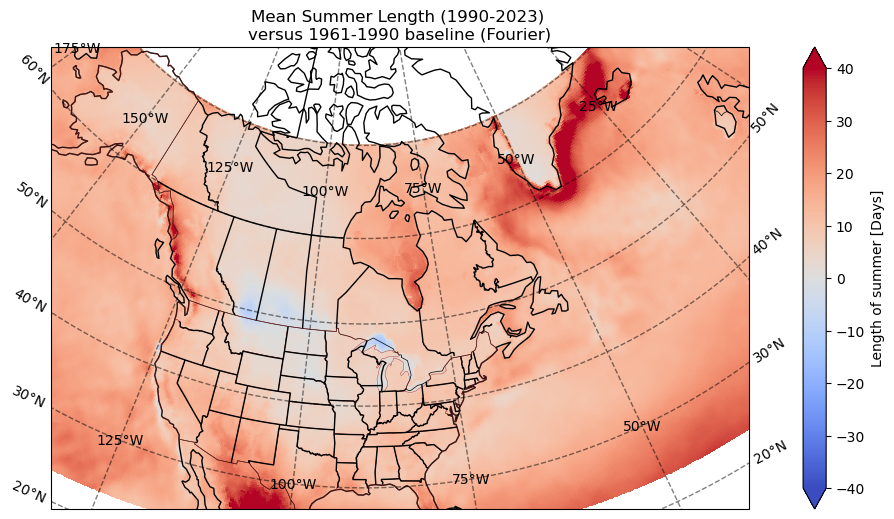

In [9]:
# will this work?


central_longitude = -90#-(91 + 52 / 60)
central_latitude = 60

############
#Global map of accheat anomaly
fig = plt.figure(figsize=(14,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = midlat_land_length_anom.plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-40,
    vmax=40, # define range to include an entire year
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    
)


ax.set_extent((-130, -40, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)

#fig.colorbar(dataplot).remove()
#plt.colorbar(dataplot2,label="Summer Acc Heat Anomaly (deg-days)", pad=0.11)

#fig.colorbar(label="Day of year difference",              shrink=0.55, pad=0.11             )

plt.title("Mean Summer Length (1990-2023) \nversus 1961-1990 baseline (Fourier)")
#plt.savefig("./Plots/"+str(input_year)+"_SummerHeat_global.png")
plt.show()



## Europe

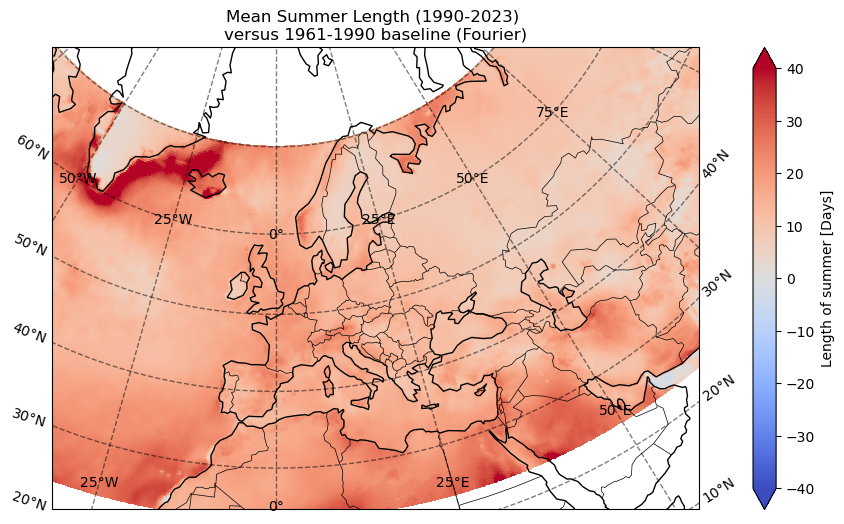

In [10]:



central_longitude = 0
central_latitude = 60

############
#Global map of accheat anomaly
fig = plt.figure(figsize=(14,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = midlat_land_length_anom.plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-40,
    vmax=40, # define range to include an entire year
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    
)


ax.set_extent((-30, 60, 20, 75))

# provinces_50m = cfeature.NaturalEarthFeature('cultural',
#                                              'admin_1_states_provinces_lines',
#                                              '50m',
#                                              facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
# ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
# ax.add_feature(provinces_50m)

#fig.colorbar(dataplot).remove()
#plt.colorbar(dataplot2,label="Summer Acc Heat Anomaly (deg-days)", pad=0.11)

#fig.colorbar(label="Day of year difference",              shrink=0.55, pad=0.11             )

plt.title("Mean Summer Length (1990-2023) \nversus 1961-1990 baseline (Fourier)")
#plt.savefig("./Plots/"+str(input_year)+"_SummerHeat_global.png")
plt.show()



In [12]:
ds_base = ds_full_length.sel(time=slice('1961','1990'))
ds = ds_full_length.sel(time=slice('1994','2023'))

# Vancouver
input_lat = 49.246
input_lon = -123.116
van_length_analysis = ds.sel(lat=input_lat, lon=input_lon, method="nearest")
van_length_base = ds_base.sel(lat=input_lat, lon=input_lon, method="nearest")
# t-test
statres, pval = stats.ttest_rel(van_length_analysis, van_length_base)
print("Van p-val: "+str(np.round(pval,4)))

# Barcelona
input_lat = 41.38879000
input_lon = 2.15899000
bar_length_analysis = ds.sel(lat=input_lat, lon=input_lon, method="nearest")
bar_length_base = ds_base.sel(lat=input_lat, lon=input_lon, method="nearest")
# t-test
statres, pval = stats.ttest_rel(bar_length_analysis, bar_length_base)
print("Bar p-val: "+str(np.round(pval,4)))

# Beijing
input_lat = 39.9075
input_lon = 116.39723
bei_length_analysis = ds.sel(lat=input_lat, lon=input_lon, method="nearest")
bei_length_base = ds_base.sel(lat=input_lat, lon=input_lon, method="nearest")
# t-test
statres, pval = stats.ttest_rel(bei_length_analysis, bei_length_base)
print("Bei p-val: "+str(np.round(pval,4)))

# Sydney
# test for Sydney
input_lat = -33.86785
input_lon = 151.0
syd_length_analysis = ds.sel(lat=input_lat, lon=input_lon, method="nearest")
syd_length_base = ds_base.sel(lat=input_lat, lon=input_lon, method="nearest")
# t-test
statres, pval = stats.ttest_rel(syd_length_analysis, syd_length_base)
print("Syd p-val: "+str(np.round(pval,4)))

# Santiago
input_lat = -33.45694000
input_lon = -70.64827000
san_length_analysis = ds.sel(lat=input_lat, lon=input_lon, method="nearest")
san_length_base = ds_base.sel(lat=input_lat, lon=input_lon, method="nearest")
# t-test
statres, pval = stats.ttest_rel(san_length_analysis, san_length_base)
print("San p-val: "+str(np.round(pval,4)))


Van p-val: 0.0002
Bar p-val: 0.0
Bei p-val: 0.0
Syd p-val: 0.0205
San p-val: 0.9346


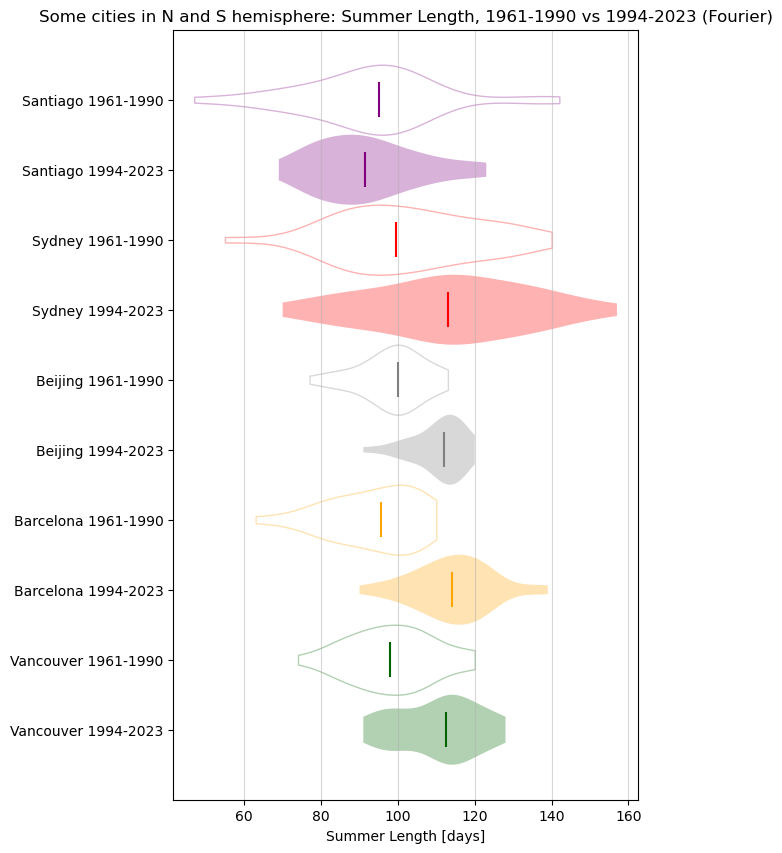

In [13]:
# violin plot customization from https://stackoverflow.com/questions/26291479/changing-the-color-of-matplotlibs-violin-plots
labels=['Vancouver 1994-2023','Vancouver 1961-1990',
        'Barcelona 1994-2023','Barcelona 1961-1990',
        'Beijing 1994-2023','Beijing 1961-1990',
        'Sydney 1994-2023','Sydney 1961-1990',
        'Santiago 1994-2023','Santiago 1961-1990'
        ]

colors = ['darkgreen','darkgreen','orange','orange','gray','gray','red','red','purple','purple']
data = [van_length_analysis, van_length_base, 
        bar_length_analysis, bar_length_base,
        bei_length_analysis, bei_length_base,
        syd_length_analysis, syd_length_base,
       san_length_analysis, san_length_base
       ]


fig, ax = plt.subplots(1, 1, figsize=(6,10))
plots = ax.violinplot(data, vert=False, showmedians=True, showextrema=False, widths=1)
for i, (pc,color) in enumerate(zip(plots['bodies'], colors)):
    if i % 2 == 0:
        pc.set_facecolor(color)
    else:
        pc.set_edgecolor(color)
        pc.set_facecolor('white')

# Set the color of the median lines
plots['cmedians'].set_colors(colors)

ax.set_xlabel("Summer Length [days]")
ax.set_yticks(np.arange(1,len(labels)+1),labels=labels)
#ax.set_xticks(np.arange(140,300,10))
plt.grid(axis="x", which='both', alpha=0.5)
plt.title("Some cities in N and S hemisphere: Summer Length, 1961-1990 vs 1994-2023 (Fourier)")
plt.show()


## T-test p-vals suggest that for all cities but Santiago those differences are significant!

# Try linear trends over time to see slope and significance of trends

Text(0, 0.5, 'Length [$Days$]')

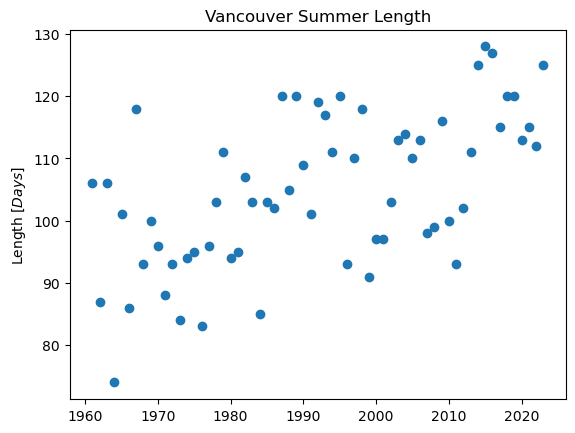

In [14]:
# plot the time series of Summer Length for Vancouver
plt.scatter(ds_full_length.time, ds_full_length.sel(lat=49.25, lon=-123).values)
plt.title("Vancouver Summer Length")
plt.ylabel("Length [$Days$]")

In [15]:
x = ds_full_length.time.dt.year.values
y = ds_full_length.sel(lat=49.25, lon=-123).values

x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.343
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     31.87
Date:                Mon, 20 Jan 2025   Prob (F-statistic):           4.57e-07
Time:                        09:37:52   Log-Likelihood:                -233.83
No. Observations:                  63   AIC:                             471.7
Df Residuals:                      61   BIC:                             475.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -679.1006    138.872     -4.890      0.0

In [16]:
model.pvalues[1], model.params[1], model.rsquared

(np.float64(4.57330561696061e-07),
 np.float64(0.3935291858679002),
 np.float64(0.34314510819022415))

#### using pymannkendall package to perform mann-kendall test for significance of trends <br> Hussain et al., (2019). pyMannKendall: a python package for non parametric Mann Kendall family of trend tests.. Journal of Open Source Software, 4(39), 1556, https://doi.org/10.21105/joss.01556 <br><br> Examples: https://github.com/mmhs013/pyMannKendall/blob/master/Examples/Example_pyMannKendall.ipynb <br> https://www.statology.org/mann-kendall-test-python/

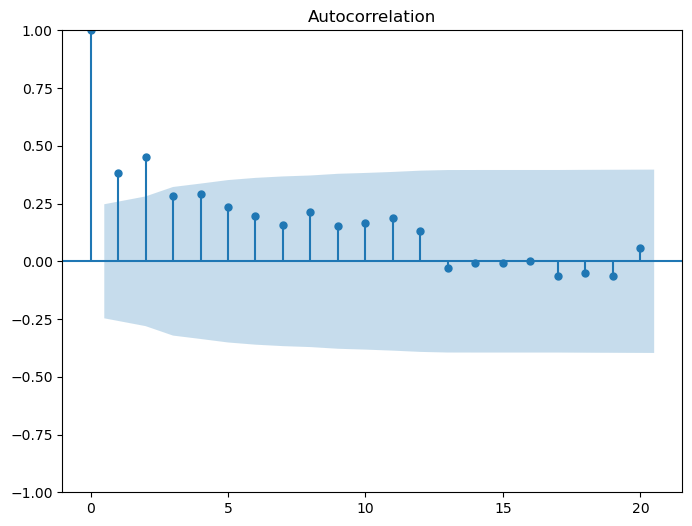

In [17]:
# autocorrelation test from statsmodels
# https://www.statology.org/autocorrelation-python/
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.tsa.plot_acf(y, lags=20, ax=ax);

### The first few lags (1 & 2 yrs) show serial autocorrelation so we need to run a modified Mann-Kendall test - try both Hamed & Rao, and Yue & Wang

In [18]:
result_orig = mk.original_test(y)
result_hr = mk.hamed_rao_modification_test(y)
result_yw = mk.yue_wang_modification_test(y)
print(result_orig,'\n\n', result_hr,'\n\n', result_yw)

Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(3.44270135843594e-06), z=np.float64(4.642469101114278), Tau=np.float64(0.4009216589861751), s=np.float64(783.0), var_s=np.float64(28373.666666666668), slope=np.float64(0.41379310344827586), intercept=np.float64(90.17241379310344)) 

 Modified_Mann_Kendall_Test_Hamed_Rao_Approach(trend='increasing', h=np.True_, p=np.float64(3.44270135843594e-06), z=np.float64(4.642469101114278), Tau=np.float64(0.4009216589861751), s=np.float64(783.0), var_s=np.float64(28373.666666666668), slope=np.float64(0.41379310344827586), intercept=np.float64(90.17241379310344)) 

 Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(10.870769732219104), Tau=np.float64(0.4009216589861751), s=np.float64(783.0), var_s=np.float64(5174.792179493699), slope=np.float64(0.41379310344827586), intercept=np.float64(90.17241379310344))


In [19]:
# extract h-value (true if there is a trend) and p-value from tests
print(result_hr.h, result_hr.p)

True 3.44270135843594e-06


#### Looks like I can apply the test for each grid cell over time - will be interesting to see how this affects the runtime

## Linear fit of Summer Length over Time for every grid cell

In [20]:
%%time

# takes 13 min for 63 years without Mann-Kendall test
# takes 32 min for 63 years with MK test!

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_full_length.lat.values[:num_lat]
loop_lons = ds_full_length.lon.values[:num_lon]

# empty data arrays for summer stats
length_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
length_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
length_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
length_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
length_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
length_slope.attrs["long_name"] = "Slope of linear fit of summer length over time"
length_slope.attrs["units"] = "Days/year"

length_pval.attrs["long_name"] = "p-value of linear fit"
length_pval.attrs["units"] = "None"

length_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
length_r2.attrs["units"] = "None"

length_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
length_mkh.attrs["units"] = "Binary"

length_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
length_mkp.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_full_length.time.dt.year.values
        y = ds_full_length.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())

        # load up data arrays with fit values
        length_slope.loc[input_lat, input_lon] = model.params[1]

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        length_mkh.loc[input_lat, input_lon] = result_mk.h
        length_mkp.loc[input_lat, input_lon] = result_mk.p

        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if np.isnan(model.pvalues[1]):
            length_pval.loc[input_lat, input_lon] = 1
            length_r2.loc[input_lat, input_lon] = 0
        else:
            # otherwise fit pvalue and r2 are OK
            length_pval.loc[input_lat, input_lon] = model.pvalues[1]
            length_r2.loc[input_lat, input_lon] = model.rsquared
        
# results dataset
results_ds = xr.Dataset(data_vars={'LengthSlope':length_slope,
                           'LengthPvalue':length_pval,
                           'LengthR2':length_r2,
                           'LengthMKH':length_mkh,
                           'LengthMKP':length_mkp}
                       )

# see results
results_ds

CPU times: user 30min, sys: 2min 26s, total: 32min 27s
Wall time: 32min 29s


<xarray.Dataset> Size: 42MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    LengthSlope   (lat, lon) float64 8MB 0.07215 0.07215 0.07215 ... 0.186 0.186
    LengthPvalue  (lat, lon) float64 8MB 0.04096 0.04096 ... 1.989e-07 1.989e-07
    LengthR2      (lat, lon) float64 8MB 0.06671 0.06671 ... 0.3604 0.3604
    LengthMKH     (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    LengthMKP     (lat, lon) float64 8MB 0.02691 0.02691 0.02691 ... 0.0 0.0 0.0

### Full plot with all p-values

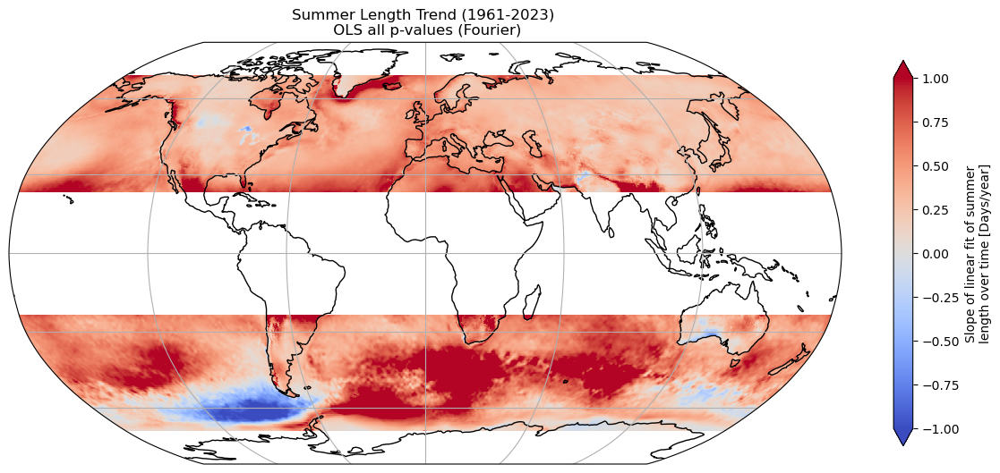

In [22]:

# Global summer length trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.7}
)



plt.title("Summer Length Trend (1961-2023) \n OLS all p-values (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

### plot with hatching for where MK test says less than alpha = 0.05

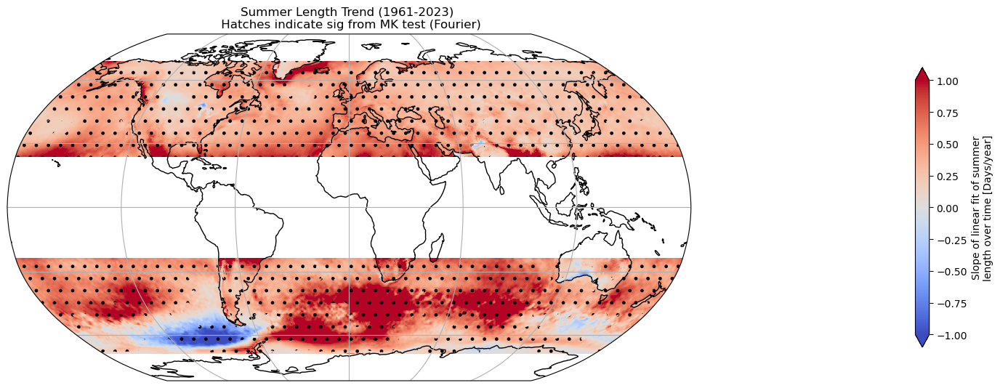

In [24]:

# Global summer length trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer Length Trend (1961-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

## Filtered for p-values < 0.05 (no correction)

In [25]:

# # Global summer length trend
# fig = plt.figure(figsize=(15,8))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines()

# results_ds.LengthSlope.where((results_ds.LengthPvalue <= 0.05) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-1.5,
#     vmax=1.5, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
#     cbar_kwargs={'shrink': 0.5}
# )

# plt.title("Summer Length Trend (1961-2023) \n OLS p-value < 0.05")#+" using 1961-1990 baseline")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
# plt.tight_layout()
# plt.show()

In [26]:

# central_longitude = -(91 + 52 / 60)
# central_latitude = 40

# ############
# #Global map of tmax anomaly
# fig = plt.figure(figsize=(15,9))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

# dataplot = results_ds.LengthSlope.where((results_ds.LengthPvalue <= 0.05) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-1.5,
#     vmax=1.5, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
#     cbar_kwargs={'shrink': 0.5}
    
# )
# ax.set_extent((-130, -60, 20, 75))

# provinces_50m = cfeature.NaturalEarthFeature('cultural',
#                                              'admin_1_states_provinces_lines',
#                                              '50m',
#                                              facecolor='none')
# ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
# ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
# ax.add_feature(provinces_50m)

# plt.title("Summer Length Trend (1961-2023) \n OLS p-value < 0.05")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerHeat_global.png")
# plt.show()



## Apply False Discovery Rate correction to p-values <br> https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html

In [27]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds.LengthPvalue.values)

# add as variable to dataset
results_ds['LengthPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds

<xarray.Dataset> Size: 50MB
Dimensions:        (lat: 721, lon: 1440)
Coordinates:
  * lat            (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon            (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    LengthSlope    (lat, lon) float64 8MB 0.07215 0.07215 ... 0.186 0.186
    LengthPvalue   (lat, lon) float64 8MB 0.04096 0.04096 ... 1.989e-07
    LengthR2       (lat, lon) float64 8MB 0.06671 0.06671 ... 0.3604 0.3604
    LengthMKH      (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    LengthMKP      (lat, lon) float64 8MB 0.02691 0.02691 0.02691 ... 0.0 0.0
    LengthPvalFDR  (lat, lon) float64 8MB 0.0504 0.05049 ... 8.058e-07 8.147e-07

## Plot using FDR correction on p-values, now with a threshold of 0.1 AND results from MK test


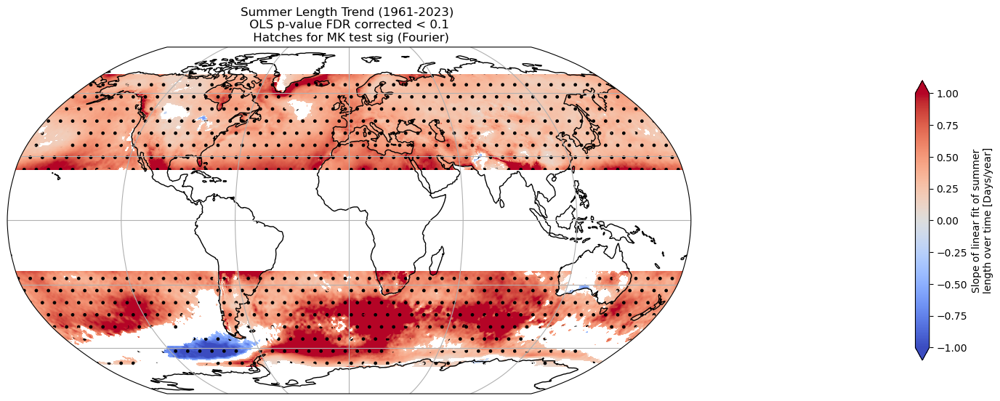

In [28]:

# Global summer length trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.LengthSlope.where((results_ds.LengthPvalFDR <= 0.1) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer Length Trend (1961-2023) \n OLS p-value FDR corrected < 0.1 \n Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

### North America

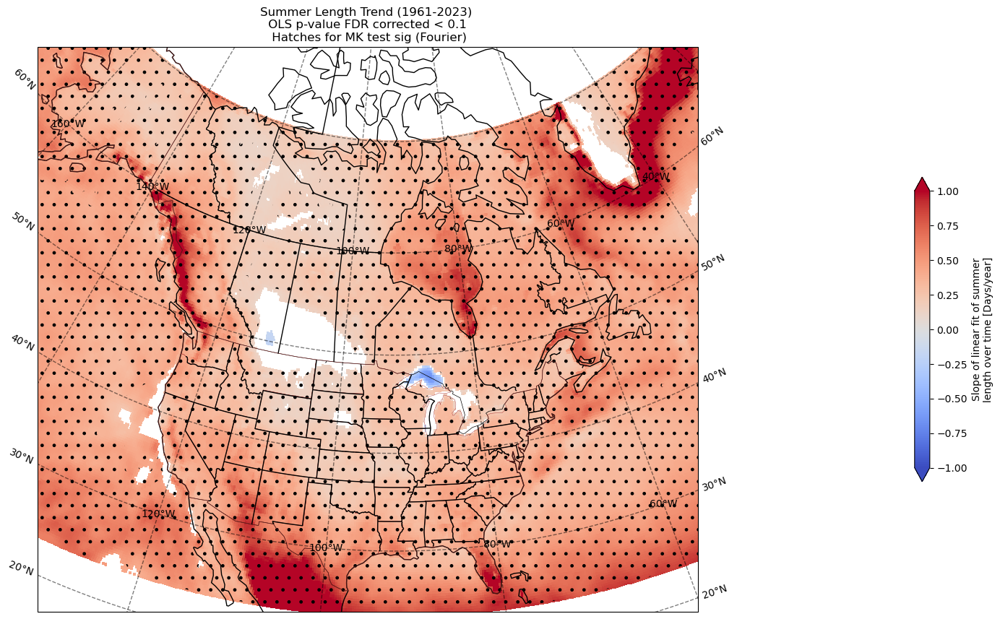

In [29]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of tmax anomaly
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.LengthSlope.where((results_ds.LengthPvalFDR <= 0.1) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.0,
    vmax=1.0, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Summer Length Trend (1961-2023) \n OLS p-value FDR corrected < 0.1 \n Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()



### MK test sig only

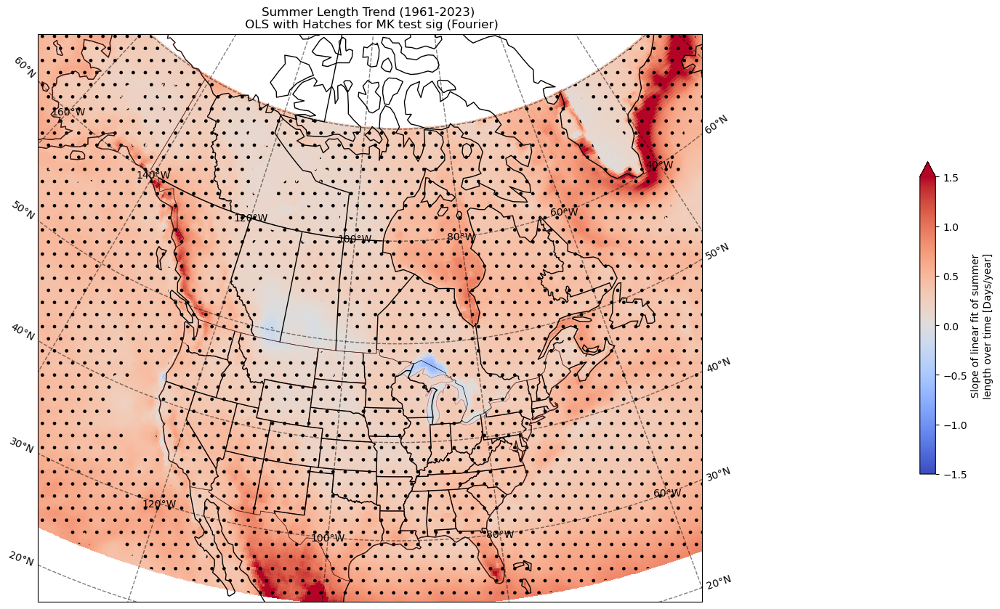

In [30]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of tmax anomaly
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.LengthSlope.where( (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.5,
    vmax=1.5, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Summer Length Trend (1961-2023) \n OLS with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()



### Europe with MK hatching

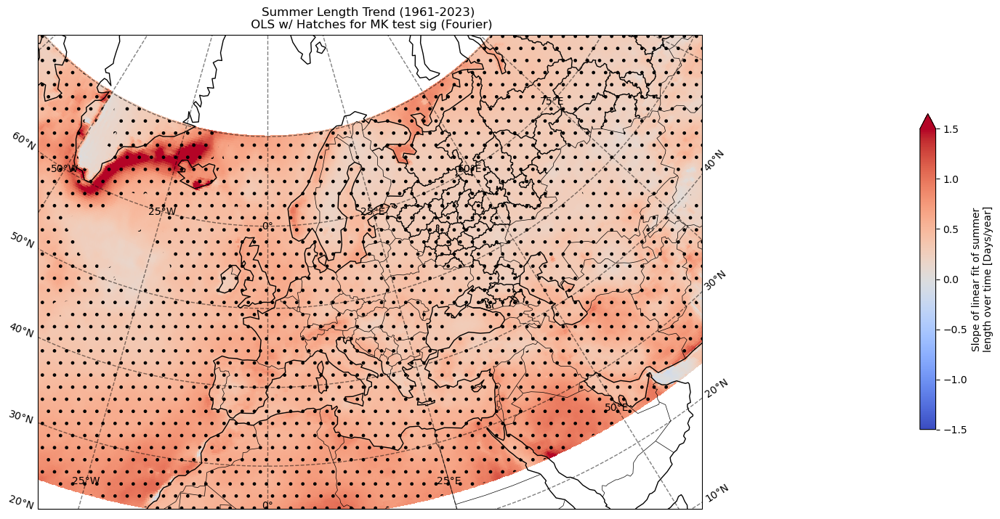

In [31]:
central_longitude = 0
central_latitude = 40

############
#Global map of tmax anomaly
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.5,
    vmax=1.5, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

ax.set_extent((-30, 60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)

plt.title("Summer Length Trend (1961-2023) \n OLS w/ Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()



# Now do same analysis for Summer Length trends over analysis period: 1990-2023

In [32]:
# restrict to 1990-2023
ds_length_analysis = ds_full_length.sel(time=slice('1990','2023'))
ds_length_analysis
                                    

<xarray.DataArray 'SummerLength' (time: 34, lat: 721, lon: 1440)> Size: 282MB
[35300160 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days

### Linear trends for each grid cell 1990-2023

In [33]:
%%time

# takes 9 min for 34 years
# takes 28 min for 34 years w/ MK test

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_length_analysis.lat.values[:num_lat]
loop_lons = ds_length_analysis.lon.values[:num_lon]

# empty data arrays for summer stats
length_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
length_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
length_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
length_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
length_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# add attributes
length_slope.attrs["long_name"] = "Slope of linear fit of summer length over time"
length_slope.attrs["units"] = "Days/year"

length_pval.attrs["long_name"] = "p-value of linear fit"
length_pval.attrs["units"] = "None"

length_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
length_r2.attrs["units"] = "None"

length_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
length_mkh.attrs["units"] = "Binary"

length_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
length_mkp.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_length_analysis.time.dt.year.values
        y = ds_length_analysis.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())
        
        # load up data arrays with fit values
        length_slope.loc[input_lat, input_lon] = model.params[1]


        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        length_mkh.loc[input_lat, input_lon] = result_mk.h
        length_mkp.loc[input_lat, input_lon] = result_mk.p

        
        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if (np.isnan(model.pvalues[1]) | np.isnan(model.rsquared)):
            print("This one has nans: "+str(input_lat)+","+str(input_lon))
            length_pval.loc[input_lat, input_lon] = 1.0
            length_r2.loc[input_lat, input_lon] = 0.0
        else:
            # otherwise fit pvalue and r2 are OK
            length_pval.loc[input_lat, input_lon] = model.pvalues[1]
            length_r2.loc[input_lat, input_lon] = model.rsquared
        
# results dataset
results_ds_an = xr.Dataset(data_vars={'LengthSlope':length_slope,
                           'LengthPvalue':length_pval,
                           'LengthR2':length_r2,
                           'LengthMKH':length_mkh,
                           'LengthMKP':length_mkp}
                           )

# see results
results_ds_an

CPU times: user 25min 36s, sys: 1min 32s, total: 27min 8s
Wall time: 27min 15s


<xarray.Dataset> Size: 42MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    LengthSlope   (lat, lon) float64 8MB 0.02842 0.02842 ... 0.1485 0.1485
    LengthPvalue  (lat, lon) float64 8MB 0.7553 0.7553 0.7553 ... 0.1156 0.1156
    LengthR2      (lat, lon) float64 8MB 0.003079 0.003079 ... 0.07557 0.07557
    LengthMKH     (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    LengthMKP     (lat, lon) float64 8MB 0.4964 0.4964 ... 0.02122 0.02122

In [34]:
# diagnose scalar divide warning on some cells - this should be zero so we can do FDR correction
np.count_nonzero(np.isnan(results_ds_an.LengthPvalue.values))

0

### Apply FDR correction to p-values

In [35]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_an.LengthPvalue.values)

# add as variable to dataset
results_ds_an['LengthPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_an

<xarray.Dataset> Size: 50MB
Dimensions:        (lat: 721, lon: 1440)
Coordinates:
  * lat            (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon            (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    LengthSlope    (lat, lon) float64 8MB 0.02842 0.02842 ... 0.1485 0.1485
    LengthPvalue   (lat, lon) float64 8MB 0.7553 0.7553 0.7553 ... 0.1156 0.1156
    LengthR2       (lat, lon) float64 8MB 0.003079 0.003079 ... 0.07557 0.07557
    LengthMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    LengthMKP      (lat, lon) float64 8MB 0.4964 0.4964 ... 0.02122 0.02122
    LengthPvalFDR  (lat, lon) float64 8MB 0.7892 0.7858 0.7858 ... 0.1597 0.1594

### Write the length trend results out for later re-use

In [7]:
# write those results out for later use
# output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_LengthTrends.nc'
# results_ds.to_netcdf(output_path)

# output_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2023_LengthTrends.nc'
# results_ds_an.to_netcdf(output_path2)

# read them back in, in case I am jumping to here in the script
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_LengthTrends.nc'
results_ds = xr.open_dataset(input_path)

input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2023_LengthTrends.nc'
results_ds_an = xr.open_dataset(input_path2)

## Plotting: Summer Length Trends 1990-2023 no p-value filtering

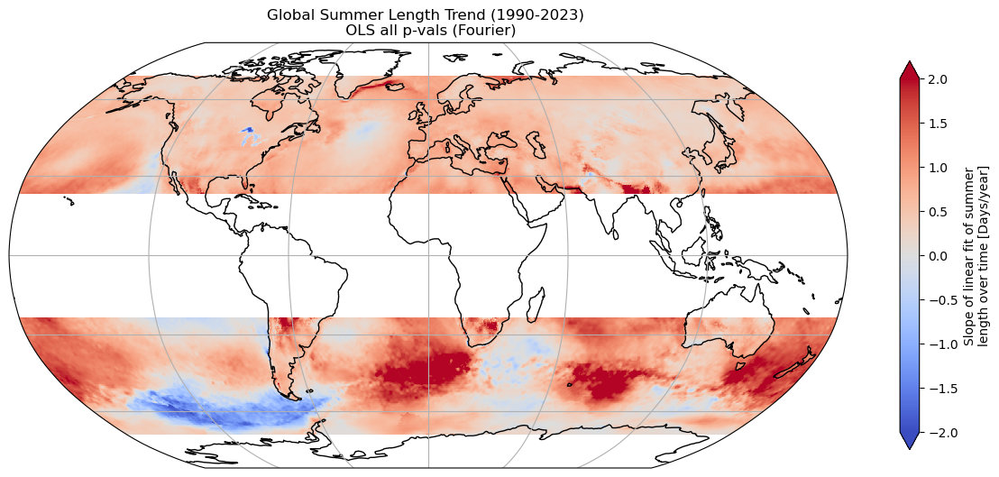

In [8]:

# Global summer length trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds_an.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-2,
    vmax=2, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.7}
)

plt.title("Global Summer Length Trend (1990-2023) \n OLS all p-vals (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

### plot with hatching for where MK test says less than alpha = 0.05

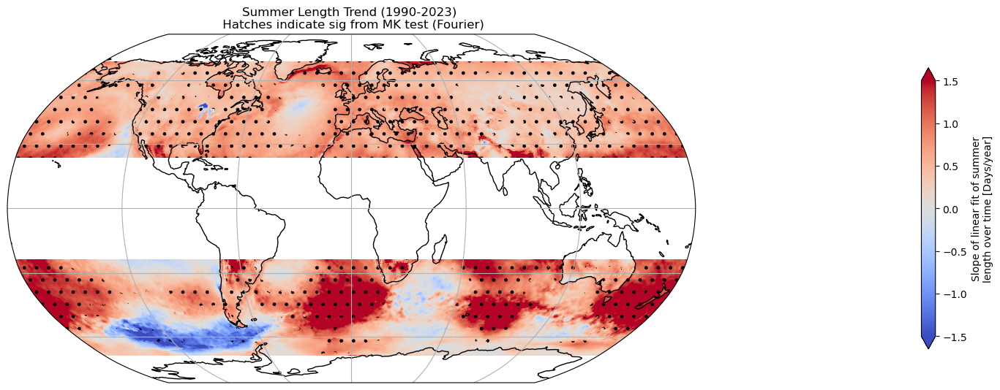

In [9]:

# Global summer length trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds_an.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.5,
    vmax=1.5, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds_an.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer Length Trend (1990-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

## Summer Length Trends 1990-2023 with FDR correction and MK test

In [10]:

# # Global summer length trend
# fig = plt.figure(figsize=(15,8))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines()

# results_ds_an.LengthSlope.where((results_ds.LengthPvalFDR <= 0.1) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-2,
#     vmax=2, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm",
#     cbar_kwargs={'shrink': 0.5}
# )

# # points with MK test p-value under 0.05
# mksig = results_ds_an.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

# mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
#                                         #colors='none', 
#                                         cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()

# plt.title("Summer Length Trend (1990-2023) \n OLS p-value FDR corrected < 0.1 \n Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
# plt.show()

### North America FDR and MK test

#### !!! Note new scale

In [40]:

# central_longitude = -(91 + 52 / 60)
# central_latitude = 40

# ############
# #Global map of summer length
# fig = plt.figure(figsize=(15,9))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

# dataplot = results_ds_an.LengthSlope.where((results_ds.LengthPvalFDR <= 0.1) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-1.5,
#     vmax=1.5, 
#     cmap="coolwarm",
#     cbar_kwargs={'shrink': 0.5}
    
# )

# # points with MK test p-value under 0.05
# mksig = results_ds_an.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
#                               ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

# mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
#                                         #colors='none', 
#                                         cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()



# ax.set_extent((-130, -60, 20, 75))

# provinces_50m = cfeature.NaturalEarthFeature('cultural',
#                                              'admin_1_states_provinces_lines',
#                                              '50m',
#                                              facecolor='none')
# ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
# ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
# ax.add_feature(provinces_50m)
# plt.title("Summer Length Trend (1990-2023) \n OLS p-value FDR corrected < 0.1 \n Hatches for MK test sig")#+" using 1961-1990 baseline")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
# plt.tight_layout()
# #plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
# plt.show()


### North America MK test only

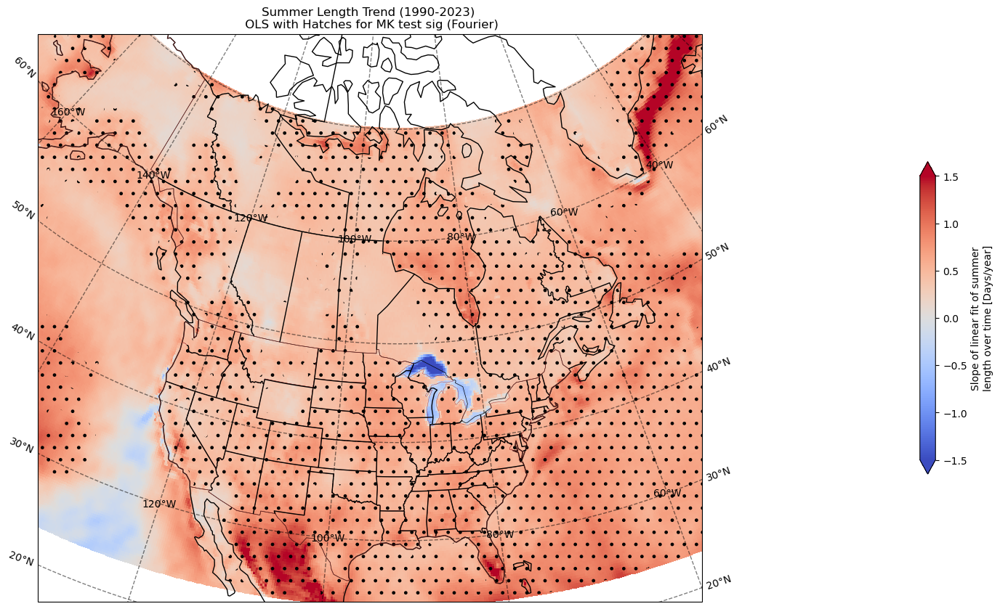

In [11]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer length
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.5,
    vmax=1.5, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds_an.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Summer Length Trend (1990-2023) \n OLS with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


### Europe with MK stat sig

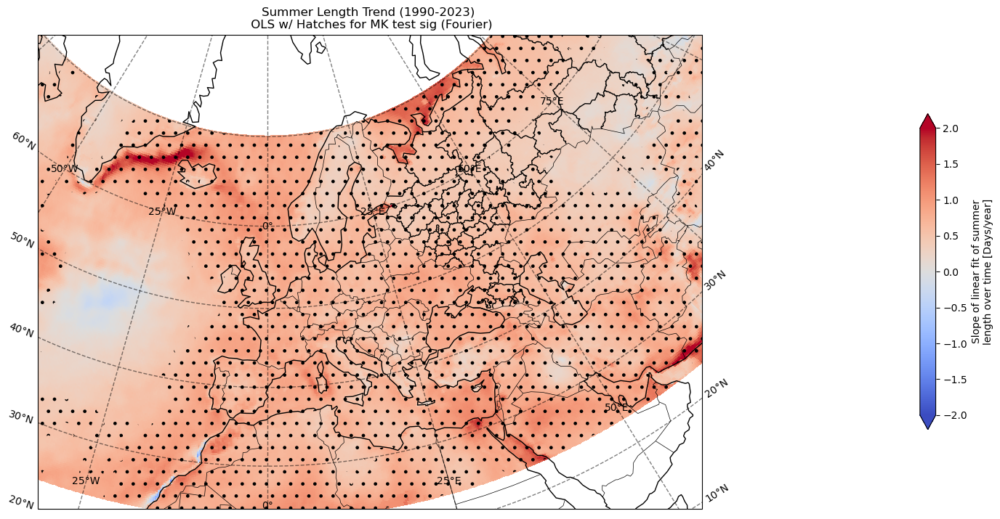

In [12]:
central_longitude = 0
central_latitude = 40

############
#Global map of summer length
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.LengthSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-2,
    vmax=2, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds_an.LengthMKP.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

ax.set_extent((-30, 60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)

plt.title("Summer Length Trend (1990-2023) \n OLS w/ Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()




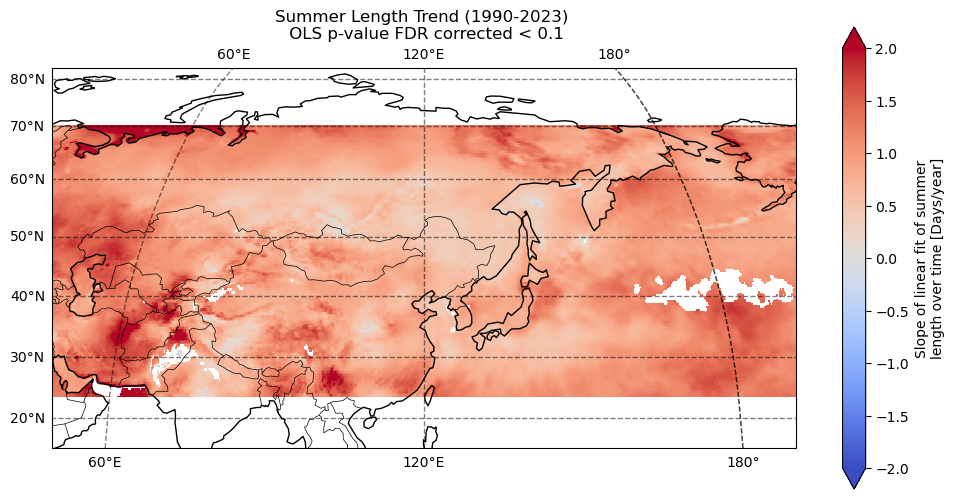

In [47]:


central_longitude = 120
central_latitude = -30

############
#Global map of summer length
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=central_longitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.LengthSlope.where((results_ds.LengthPvalFDR <= 0.1) & (((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-2,
    vmax=2, 
    cmap="coolwarm"#"YlOrRd"#cmap="coolwarm"
)
ax.set_extent((50, -170, 15, 70))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')

plt.title("Summer Length Trend (1990-2023) \n OLS p-value FDR corrected < 0.1")
#plt.savefig("./Plots/"+str(input_year)+"_SummerHeat_global.png")
plt.show()



# SummerStart Linear Trends for 1961-2023 and 1990-2023

In [13]:
ds_full_start

<xarray.DataArray 'SummerStart' (time: 63, lat: 721, lon: 1440)> Size: 523MB
[65409120 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 504B 1961-01-01 1962-01-01 ... 2023-01-01
Attributes:
    long_name:  Start day of summer for the year (DOY in [1,365])
    units:      Day of year

In [14]:
%%time

# takes 13 min for 63 years without Mann-Kendall test
# takes 32 min for 63 years with MK test!

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_full_start.lat.values[:num_lat]
loop_lons = ds_full_start.lon.values[:num_lon]

# empty data arrays for summer stats
start_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
start_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
start_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
start_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
start_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
start_slope.attrs["long_name"] = "Slope of linear fit of summer start over time"
start_slope.attrs["units"] = "Days/year"

start_pval.attrs["long_name"] = "p-value of linear fit"
start_pval.attrs["units"] = "None"

start_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
start_r2.attrs["units"] = "None"

start_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
start_mkh.attrs["units"] = "Binary"

start_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
start_mkp.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_full_start.time.dt.year.values
        y = ds_full_start.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())

        # load up data arrays with fit values
        start_slope.loc[input_lat, input_lon] = model.params[1]

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        start_mkh.loc[input_lat, input_lon] = result_mk.h
        start_mkp.loc[input_lat, input_lon] = result_mk.p

        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if np.isnan(model.pvalues[1]):
            start_pval.loc[input_lat, input_lon] = 1
            start_r2.loc[input_lat, input_lon] = 0
        else:
            # otherwise fit pvalue and r2 are OK
            start_pval.loc[input_lat, input_lon] = model.pvalues[1]
            start_r2.loc[input_lat, input_lon] = model.rsquared
        
# results dataset
results_ds = xr.Dataset(data_vars={'StartSlope':start_slope,
                           'StartPvalue':start_pval,
                           'StartR2':start_r2,
                           'StartMKH':start_mkh,
                           'StartMKP':start_mkp}
                       )

# see results
results_ds

CPU times: user 30min 17s, sys: 2min 29s, total: 32min 46s
Wall time: 33min 13s


<xarray.Dataset> Size: 42MB
Dimensions:      (lat: 721, lon: 1440)
Coordinates:
  * lat          (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon          (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartSlope   (lat, lon) float64 8MB -0.09274 -0.09274 ... -0.1028 -0.1028
    StartPvalue  (lat, lon) float64 8MB 0.000508 0.000508 ... 2.73e-05 2.73e-05
    StartR2      (lat, lon) float64 8MB 0.1811 0.1811 0.1811 ... 0.2523 0.2523
    StartMKH     (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    StartMKP     (lat, lon) float64 8MB 0.001252 0.001252 ... 3.52e-05 3.52e-05

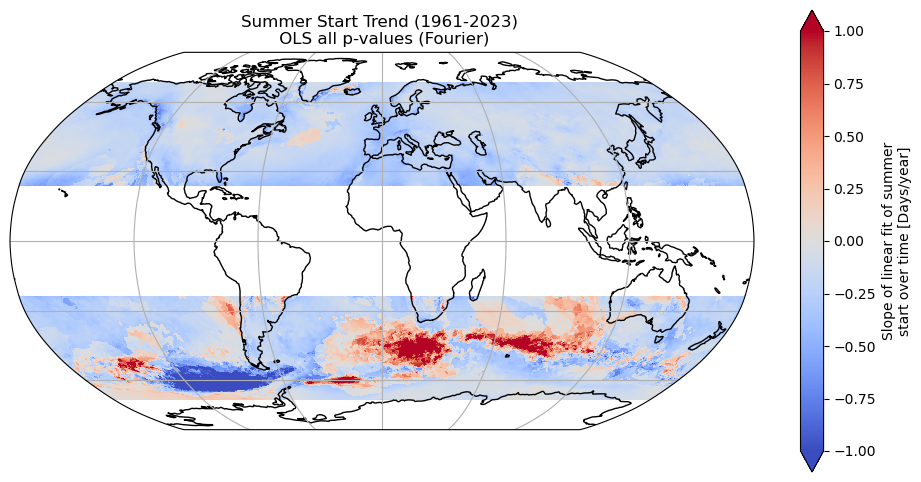

In [16]:

# Global summer start trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.StartSlope.where((((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.0,
    vmax=1.0, 
    cmap="coolwarm"#"YlOrRd"#cmap="coolwarm"
)

plt.title("Summer Start Trend (1961-2023) \n OLS all p-values (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

## Apply False Discovery Rate correction to p-values

In [17]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds.StartPvalue.values)

# add as variable to dataset
results_ds['StartPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds

<xarray.Dataset> Size: 50MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartSlope    (lat, lon) float64 8MB -0.09274 -0.09274 ... -0.1028 -0.1028
    StartPvalue   (lat, lon) float64 8MB 0.000508 0.000508 ... 2.73e-05 2.73e-05
    StartR2       (lat, lon) float64 8MB 0.1811 0.1811 0.1811 ... 0.2523 0.2523
    StartMKH      (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    StartMKP      (lat, lon) float64 8MB 0.001252 0.001252 ... 3.52e-05 3.52e-05
    StartPvalFDR  (lat, lon) float64 8MB 0.002318 0.002348 ... 0.0002051

## Plot using FDR correction on p-values

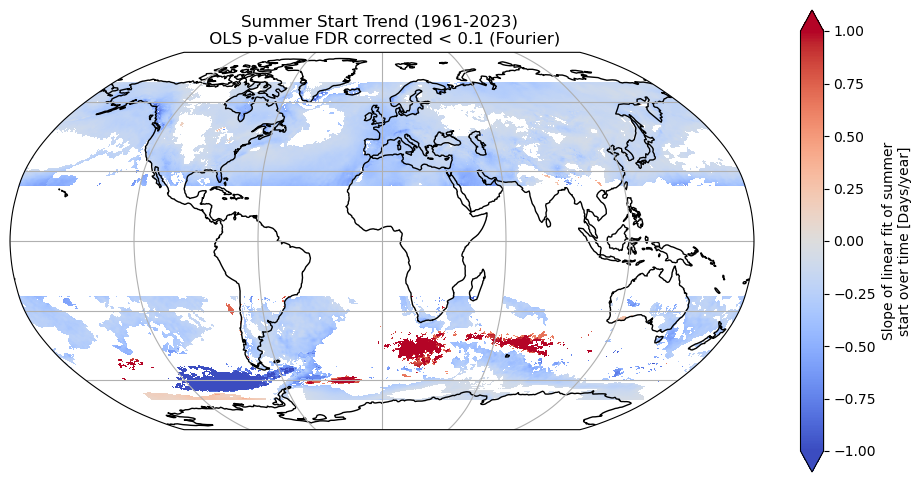

In [18]:

# Global summer start trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.StartSlope.where((results_ds.StartPvalFDR <= 0.1) & (((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.0,
    vmax=1.0, 
    cmap="coolwarm"#"YlOrRd"#cmap="coolwarm"
)

plt.title("Summer Start Trend (1961-2023) \n OLS p-value FDR corrected < 0.1 (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

## Plot with hatching from MK test

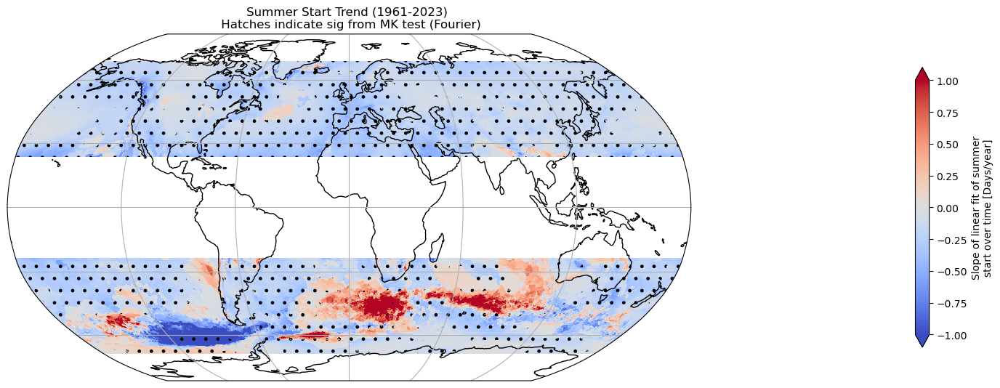

In [19]:

# Global summer start trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.StartSlope.where((((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.StartMKP.where((((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer Start Trend (1961-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

### North America MK test only

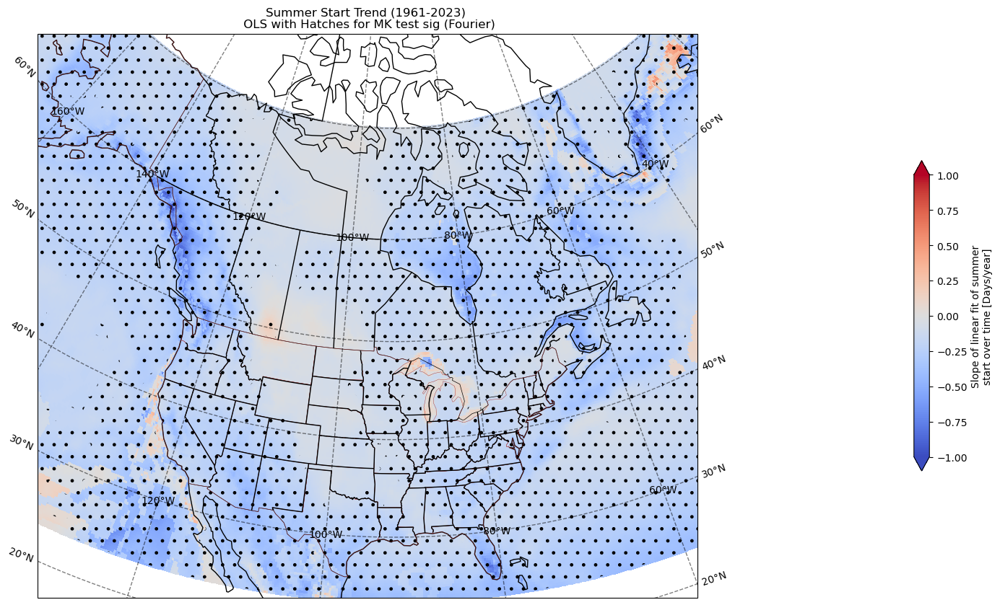

In [21]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer start
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.StartSlope.where((((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.0,
    vmax=1.0, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.StartMKP.where((((ds_full_start.lat >= 23.5) & (ds_full_start.lat <= 70)) | 
                              ((ds_full_start.lat <= -23.5) & (ds_full_start.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Summer Start Trend (1961-2023) \n OLS with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


# Summer Start trends over analysis period: 1990-2023

In [22]:
# restrict to 1990-2023
ds_start_analysis = ds_full_start.sel(time=slice('1990','2023'))
ds_start_analysis
                                    

<xarray.DataArray 'SummerStart' (time: 34, lat: 721, lon: 1440)> Size: 282MB
[35300160 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Start day of summer for the year (DOY in [1,365])
    units:      Day of year

### Linear trends for each grid cell 1990-2023

In [23]:
%%time

# takes 9 min for 34 years
# takes 27 min for 34 years w/ MK test

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_start_analysis.lat.values[:num_lat]
loop_lons = ds_start_analysis.lon.values[:num_lon]

# empty data arrays for summer stats
start_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
start_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
start_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
start_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
start_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# add attributes
start_slope.attrs["long_name"] = "Slope of linear fit of summer start over time"
start_slope.attrs["units"] = "Days/year"

start_pval.attrs["long_name"] = "p-value of linear fit"
start_pval.attrs["units"] = "None"

start_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
start_r2.attrs["units"] = "None"

start_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
start_mkh.attrs["units"] = "Binary"

start_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
start_mkp.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_start_analysis.time.dt.year.values
        y = ds_start_analysis.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())
        
        # load up data arrays with fit values
        start_slope.loc[input_lat, input_lon] = model.params[1]


        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        start_mkh.loc[input_lat, input_lon] = result_mk.h
        start_mkp.loc[input_lat, input_lon] = result_mk.p

        
        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if (np.isnan(model.pvalues[1]) | np.isnan(model.rsquared)):
            print("This one has nans: "+str(input_lat)+","+str(input_lon))
            start_pval.loc[input_lat, input_lon] = 1.0
            start_r2.loc[input_lat, input_lon] = 0.0
        else:
            # otherwise fit pvalue and r2 are OK
            start_pval.loc[input_lat, input_lon] = model.pvalues[1]
            start_r2.loc[input_lat, input_lon] = model.rsquared
        
# results dataset
results_ds_an = xr.Dataset(data_vars={'StartSlope':start_slope,
                           'StartPvalue':start_pval,
                           'StartR2':start_r2,
                           'StartMKH':start_mkh,
                           'StartMKP':start_mkp}
                           )

# see results
results_ds_an

CPU times: user 25min 44s, sys: 1min 20s, total: 27min 4s
Wall time: 27min 5s


<xarray.Dataset> Size: 42MB
Dimensions:      (lat: 721, lon: 1440)
Coordinates:
  * lat          (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon          (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartSlope   (lat, lon) float64 8MB -0.06494 -0.06494 ... 0.01879 0.01879
    StartPvalue  (lat, lon) float64 8MB 0.2406 0.2406 0.2406 ... 0.7663 0.7663
    StartR2      (lat, lon) float64 8MB 0.04277 0.04277 ... 0.002801 0.002801
    StartMKH     (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    StartMKP     (lat, lon) float64 8MB 0.3602 0.3602 0.3602 ... 0.8694 0.8694

In [24]:
# diagnose scalar divide warning on some cells - this should be zero so we can do FDR correction
np.count_nonzero(np.isnan(results_ds_an.StartPvalue.values))

0

### Apply FDR correction to p-values

In [25]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_an.StartPvalue.values)

# add as variable to dataset
results_ds_an['StartPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_an

<xarray.Dataset> Size: 50MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartSlope    (lat, lon) float64 8MB -0.06494 -0.06494 ... 0.01879 0.01879
    StartPvalue   (lat, lon) float64 8MB 0.2406 0.2406 0.2406 ... 0.7663 0.7663
    StartR2       (lat, lon) float64 8MB 0.04277 0.04277 ... 0.002801 0.002801
    StartMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    StartMKP      (lat, lon) float64 8MB 0.3602 0.3602 0.3602 ... 0.8694 0.8694
    StartPvalFDR  (lat, lon) float64 8MB 0.3621 0.3652 0.3636 ... 0.8221 0.8251

In [26]:
# write those results out for later use
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_StartTrends.nc'
results_ds.to_netcdf(output_path)

output_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2023_StartTrends.nc'
results_ds_an.to_netcdf(output_path2)

# SummerEnd Linear Trends for 1961-2023 and 1990-2023

In [27]:
ds_full_end

<xarray.DataArray 'SummerEnd' (time: 63, lat: 721, lon: 1440)> Size: 523MB
[65409120 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 504B 1961-01-01 1962-01-01 ... 2023-01-01
Attributes:
    long_name:  Last day of summer for the year (DOY in [1,365])
    units:      Day of year

In [28]:
%%time

# takes 13 min for 63 years without Mann-Kendall test
# takes 32 min for 63 years with MK test!

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_full_end.lat.values[:num_lat]
loop_lons = ds_full_end.lon.values[:num_lon]

# empty data arrays for summer stats
end_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
end_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
end_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
end_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
end_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
end_slope.attrs["long_name"] = "Slope of linear fit of summer end over time"
end_slope.attrs["units"] = "Days/year"

end_pval.attrs["long_name"] = "p-value of linear fit"
end_pval.attrs["units"] = "None"

end_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
end_r2.attrs["units"] = "None"

end_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
end_mkh.attrs["units"] = "Binary"

end_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
end_mkp.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_full_end.time.dt.year.values
        y = ds_full_end.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())

        # load up data arrays with fit values
        end_slope.loc[input_lat, input_lon] = model.params[1]

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        end_mkh.loc[input_lat, input_lon] = result_mk.h
        end_mkp.loc[input_lat, input_lon] = result_mk.p

        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if np.isnan(model.pvalues[1]):
            end_pval.loc[input_lat, input_lon] = 1
            end_r2.loc[input_lat, input_lon] = 0
        else:
            # otherwise fit pvalue and r2 are OK
            end_pval.loc[input_lat, input_lon] = model.pvalues[1]
            end_r2.loc[input_lat, input_lon] = model.rsquared
        
# results dataset
results_ds = xr.Dataset(data_vars={'EndSlope':end_slope,
                           'EndPvalue':end_pval,
                           'EndR2':end_r2,
                           'EndMKH':end_mkh,
                           'EndMKP':end_mkp}
                       )

# see results
results_ds

CPU times: user 29min 58s, sys: 2min 24s, total: 32min 23s
Wall time: 32min 43s


<xarray.Dataset> Size: 42MB
Dimensions:    (lat: 721, lon: 1440)
Coordinates:
  * lat        (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon        (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndSlope   (lat, lon) float64 8MB -0.02059 -0.02059 ... 0.08319 0.08319
    EndPvalue  (lat, lon) float64 8MB 0.4119 0.4119 0.4119 ... 0.003722 0.003722
    EndR2      (lat, lon) float64 8MB 0.01107 0.01107 0.01107 ... 0.1298 0.1298
    EndMKH     (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    EndMKP     (lat, lon) float64 8MB 0.2407 0.2407 0.2407 ... 9.87e-05 9.87e-05

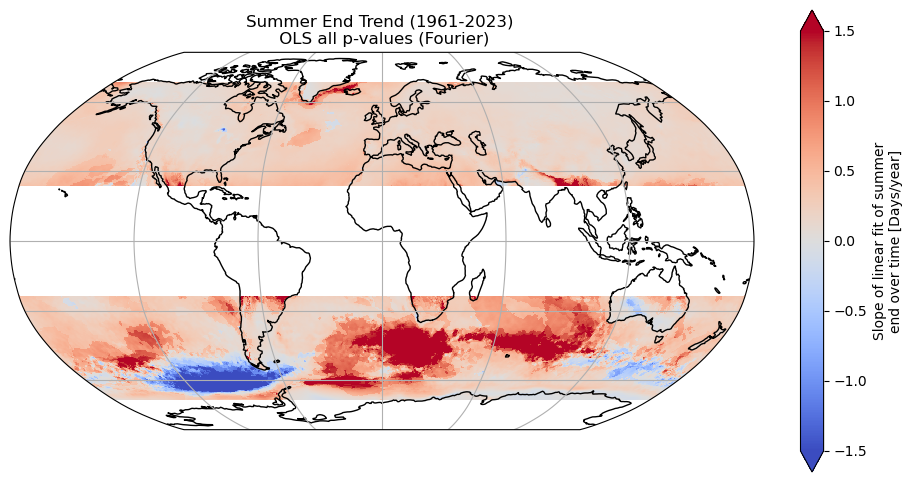

In [29]:

# Global summer end trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.EndSlope.where((((ds_full_length.lat >= 23.5) & (ds_full_length.lat <= 70)) | 
                              ((ds_full_length.lat <= -23.5) & (ds_full_length.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.5,
    vmax=1.5, 
    cmap="coolwarm"#"YlOrRd"#cmap="coolwarm"
)

plt.title("Summer End Trend (1961-2023) \n OLS all p-values (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

## Apply False Discovery Rate correction to p-values

In [30]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds.EndPvalue.values)

# add as variable to dataset
results_ds['EndPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds

<xarray.Dataset> Size: 50MB
Dimensions:     (lat: 721, lon: 1440)
Coordinates:
  * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndSlope    (lat, lon) float64 8MB -0.02059 -0.02059 ... 0.08319 0.08319
    EndPvalue   (lat, lon) float64 8MB 0.4119 0.4119 ... 0.003722 0.003722
    EndR2       (lat, lon) float64 8MB 0.01107 0.01107 0.01107 ... 0.1298 0.1298
    EndMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    EndMKP      (lat, lon) float64 8MB 0.2407 0.2407 ... 9.87e-05 9.87e-05
    EndPvalFDR  (lat, lon) float64 8MB 0.4852 0.4851 ... 0.007869 0.007945

## Plot with stat sig from MK test

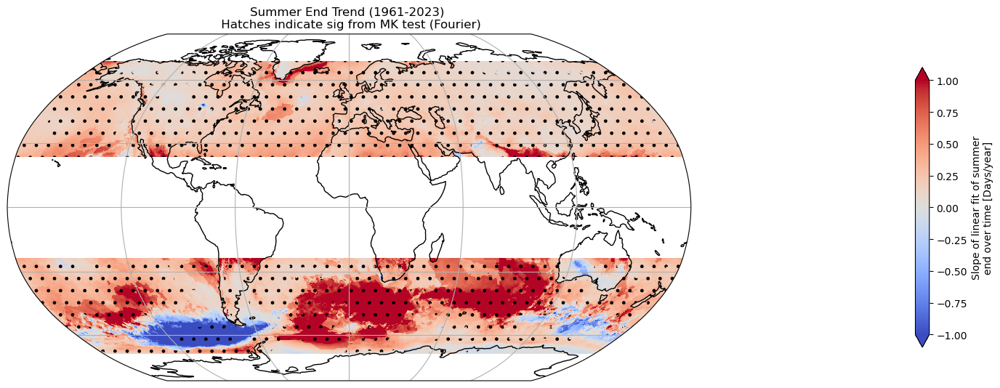

In [31]:

# Global summer end trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.EndSlope.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.EndMKP.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer End Trend (1961-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

# Summer End trends over analysis period: 1990-2023

In [33]:
# restrict to 1990-2023
ds_end_analysis = ds_full_end.sel(time=slice('1990','2023'))
ds_end_analysis
                                    

<xarray.DataArray 'SummerEnd' (time: 34, lat: 721, lon: 1440)> Size: 282MB
[35300160 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Last day of summer for the year (DOY in [1,365])
    units:      Day of year

### Linear trends for each grid cell 1990-2023

In [34]:
%%time

# takes 27 min for 34 years

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_end_analysis.lat.values[:num_lat]
loop_lons = ds_end_analysis.lon.values[:num_lon]

# empty data arrays for summer stats
end_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
end_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
end_r2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# variables for modified mann-kendall test (Hamed & Rao)
end_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
end_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# add attributes
end_slope.attrs["long_name"] = "Slope of linear fit of summer end over time"
end_slope.attrs["units"] = "Days/year"

end_pval.attrs["long_name"] = "p-value of linear fit"
end_pval.attrs["units"] = "None"

end_r2.attrs["long_name"] = "R^2 (coeff of determination) for linear fit"
end_r2.attrs["units"] = "None"

end_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
end_mkh.attrs["units"] = "Binary"

end_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
end_mkp.attrs["units"] = "None"

# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_end_analysis.time.dt.year.values
        y = ds_end_analysis.sel(lat=input_lat, lon=input_lon).values

        # OLS
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        #print(model.summary())
        
        # load up data arrays with fit values
        end_slope.loc[input_lat, input_lon] = model.params[1]


        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        end_mkh.loc[input_lat, input_lon] = result_mk.h
        end_mkp.loc[input_lat, input_lon] = result_mk.p

        
        # deal with few grid cells that return nan for Pvalue and R2 on fit
        if (np.isnan(model.pvalues[1]) | np.isnan(model.rsquared)):
            print("This one has nans: "+str(input_lat)+","+str(input_lon))
            end_pval.loc[input_lat, input_lon] = 1.0
            end_r2.loc[input_lat, input_lon] = 0.0
        else:
            # otherwise fit pvalue and r2 are OK
            end_pval.loc[input_lat, input_lon] = model.pvalues[1]
            end_r2.loc[input_lat, input_lon] = model.rsquared


# results dataset
results_ds_an = xr.Dataset(data_vars={'EndSlope':end_slope,
                           'EndPvalue':end_pval,
                           'EndR2':end_r2,
                           'EndMKH':end_mkh,
                           'EndMKP':end_mkp}
                       )

# see results
results_ds_an


CPU times: user 25min 50s, sys: 1min 23s, total: 27min 14s
Wall time: 27min 18s


<xarray.Dataset> Size: 42MB
Dimensions:    (lat: 721, lon: 1440)
Coordinates:
  * lat        (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon        (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndSlope   (lat, lon) float64 8MB -0.03652 -0.03652 ... 0.1673 0.1673
    EndPvalue  (lat, lon) float64 8MB 0.5705 0.5705 0.5705 ... 0.01493 0.01493
    EndR2      (lat, lon) float64 8MB 0.01016 0.01016 0.01016 ... 0.1714 0.1714
    EndMKH     (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    EndMKP     (lat, lon) float64 8MB 0.2801 0.2801 0.2801 ... 0.01259 0.01259

In [35]:
# diagnose scalar divide warning on some cells - this should be zero so we can do FDR correction
np.count_nonzero(np.isnan(results_ds_an.EndPvalue.values))

0

### Apply FDR correction to p-values

In [36]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_an.EndPvalue.values)

# add as variable to dataset
results_ds_an['EndPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_an

<xarray.Dataset> Size: 50MB
Dimensions:     (lat: 721, lon: 1440)
Coordinates:
  * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndSlope    (lat, lon) float64 8MB -0.03652 -0.03652 ... 0.1673 0.1673
    EndPvalue   (lat, lon) float64 8MB 0.5705 0.5705 0.5705 ... 0.01493 0.01493
    EndR2       (lat, lon) float64 8MB 0.01016 0.01016 0.01016 ... 0.1714 0.1714
    EndMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    EndMKP      (lat, lon) float64 8MB 0.2801 0.2801 0.2801 ... 0.01259 0.01259
    EndPvalFDR  (lat, lon) float64 8MB 0.628 0.629 0.6388 ... 0.02745 0.02748

### write out the summer end trend files

In [37]:
# write those results out for later use
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_EndTrends.nc'
results_ds.to_netcdf(output_path)

output_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2023_EndTrends.nc'
results_ds_an.to_netcdf(output_path2)

### Global and NA maps with MK hatching

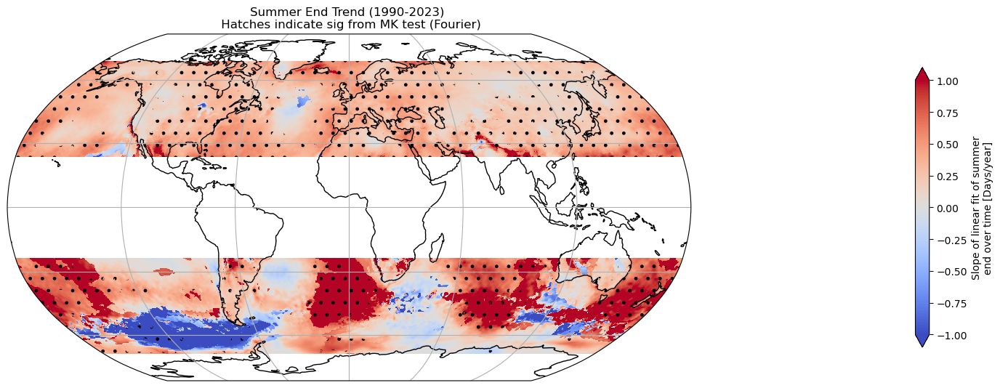

In [38]:

# Global summer end trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds_an.EndSlope.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds_an.EndMKP.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Summer End Trend (1990-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

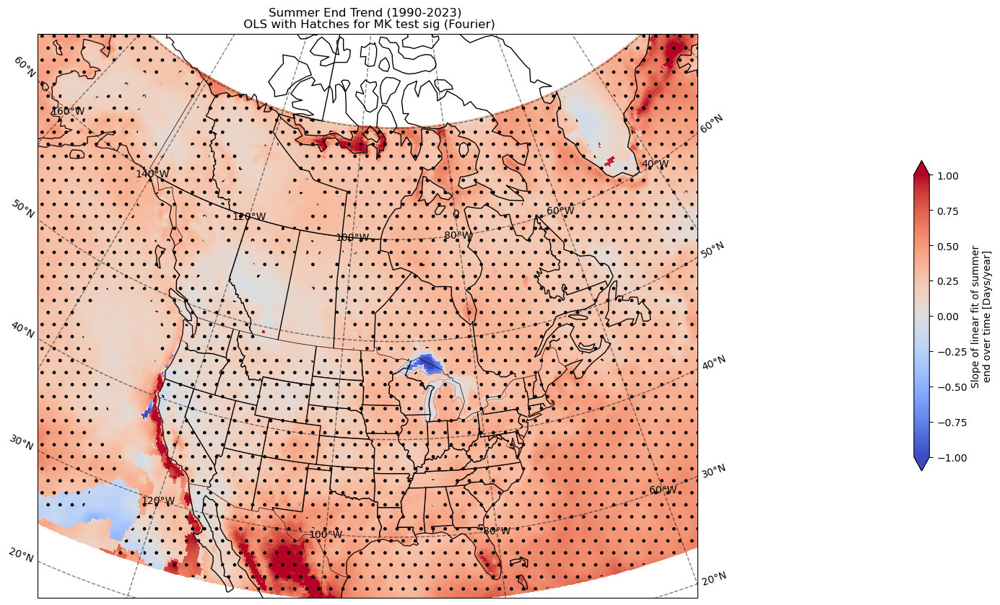

In [39]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer end
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.EndSlope.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1.0,
    vmax=1.0, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.EndMKP.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Summer End Trend (1990-2023) \n OLS with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()
